# Here we making Analysis report on **Netflix** with some simpal ways

1.   **Data understanding**

1.   **Data cleaning**
2.   **Data Analysis**


2. **Recommendations**



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as mp
import seaborn as sns
import regex as re
from datetime import datetime as dt

# Here we have import some important library for our analysis

In [2]:
data=pd.read_csv("/content/drive/MyDrive/3-Google-play-store/netflix_titles.csv.zip")


# **Data Understanding**

# Here we import **Excel** csv to use data and perform our task

In [3]:
data.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


# Here we have hvae use **Head Function** to see how our top 5 data look like and also to understand the our data more practically

In [4]:
data.tail(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


# Now here also we use **Tail Function** to understand last rows data

In [5]:
data.shape

(8807, 12)

# Here we use **Shape Function** so we can see total number of rows and columns in our data

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


# Here we use **type function** so we can see **data type** and other thing

In [7]:
data.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


# Here we have use **function isnull** to see null value in our columns

In [8]:
# data.isnull().mean()*100
round(data.isnull().sum()/len(data),2)*100

,0
show_id,0.0
type,0.0
title,0.0
director,30.0
cast,9.0
country,9.0
date_added,0.0
release_year,0.0
rating,0.0
duration,0.0


# Now we can see that how much percent data is missing from all columns and than we we see that some columns data is missing other have no null value

# **Data Cleaning**

# From here we will start our **data cleaning** and **removing null** value from data  

In [9]:
data["country"].nunique()

748

In [10]:
data['country'].isnull().sum()

np.int64(831)

In [11]:
data["country"].value_counts()

,count
country,
United States,2818
India,972
United Kingdom,419
Japan,245
South Korea,199
...,...
"Mexico, United States, Spain, Colombia",1
"Canada, Norway",1
"Finland, Germany, Belgium",1


# Here we have selected our first column name **country**

*   Here we understand some thing that there are some rows in which many country name are include which is wrong
*  So now our task is to remove this rows data and join it in orignal data  



In [12]:
data["new_country"]=data['country'].str.split(',')
data= data.explode("new_country")
data["new_country"]=data['new_country'].str.strip()
data['new_country'].value_counts()


,count
new_country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
...,...
Sudan,1
Panama,1
Uganda,1


In [13]:
data["new_country"]=data["new_country"].fillna("unknown")
data["new_country"].isnull().sum()

np.int64(0)

# Now the tak of removing many name to one name row is done

1.   We have use function like **split** and **explode** to remove and seprate data from one row
2.  After that we have use **fillna** to mark data as **unknow** who have missing value



In [14]:
data['duration'].value_counts()

,count
duration,
1 Season,1985
2 Seasons,497
3 Seasons,242
93 min,202
90 min,199
...,...
196 min,1
228 min,1
178 min,1


In [15]:
data["numeric_duration"]=data['duration'].str.extract(r'(\d+)')


In [16]:

data["movie_duration"] = data["numeric_duration"].where(data["type"]=="Movie")
data["tv_show_duration"] = data["numeric_duration"].where(data["type"]=="TV Show")


# Now we have move to another column and then we realised that we can seprate seasons and movie rows to make analysis more accurate and easy

1.   So we have seprate duration of movie and show and made different columns



In [17]:
data['rating'].unique()

array(['PG-13', 'TV-MA', 'PG', 'TV-14', 'TV-PG', 'TV-Y', 'TV-Y7', 'R',
       'TV-G', 'G', 'NC-17', '74 min', '84 min', '66 min', 'NR', nan,
       'TV-Y7-FV', 'UR'], dtype=object)

In [18]:
data["runtime"] = data["rating"].str.extract(r'(\d+)').astype(float)

In [19]:
data.loc[data["rating"].str.contains("min", na=False), "rating"] = np.nan


In [20]:
data["new_rating"]=data['rating'].fillna("no_rating")

# Now in column rating there are some rating which include **min** which is wrong and this data don't belong to this column so we have to remove it

1.   So we have seprate min from that data
2.   After seprate it we have removed it



In [21]:
data['listed_in_new']=data["listed_in"].str.split(",")
data=data.explode("listed_in_new")
data["listed_in_new"]=data["listed_in_new"].str.strip()
data["listed_in_new"].value_counts()

,count
listed_in_new,
International Movies,3513
Dramas,3202
Comedies,1981
International TV Shows,1465
Action & Adventure,1182
Documentaries,1118
Independent Movies,1040
TV Dramas,852
Children & Family Movies,845


# Now we have sperate this data also to make each category fell different and make our analysis more accurate

In [22]:
data['date_added']=pd.to_datetime(data['date_added'],errors='coerce')
data['year_added']=data['date_added'].dt.year
data['months_added']=data['date_added'].dt.month


# Again we have seprate year and months and make different columns so now we can analysis on it differently

/tmp/ipykernel_5639/3940941273.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data,x='new_country',palette='cool_r')


<Axes: title={'center': 'total number of show in country'}, xlabel='country_name', ylabel='number of show in counrty'>

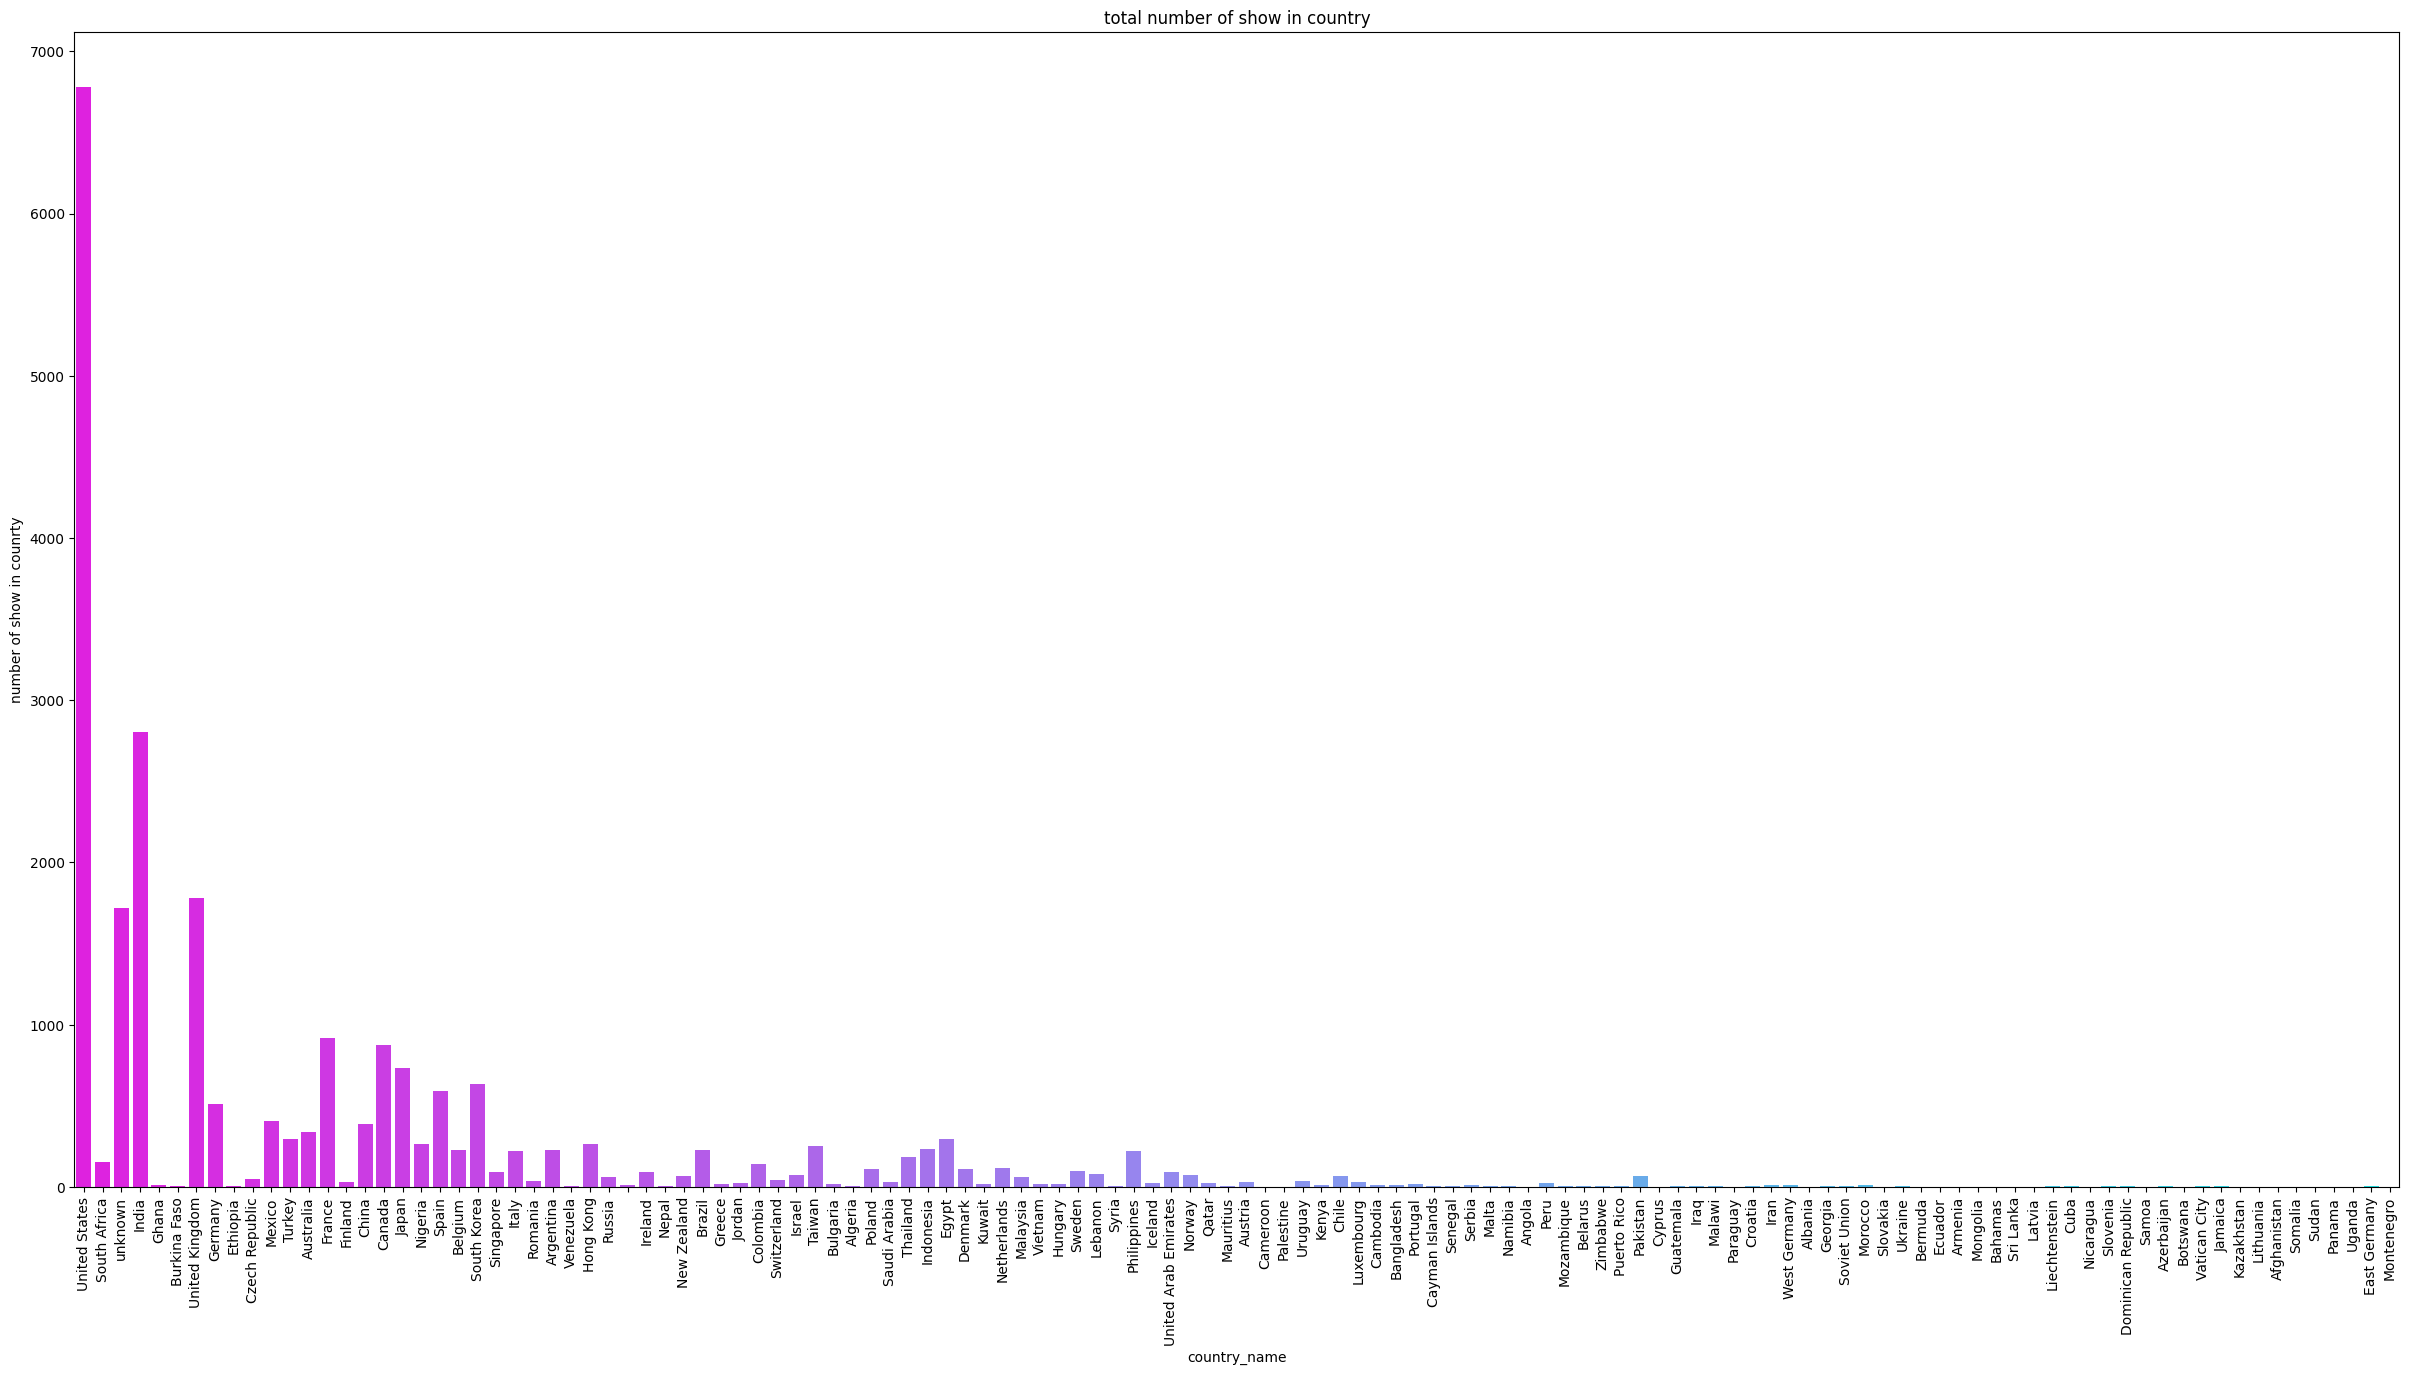

In [23]:
mp.figure(figsize=(30,15))
mp.xticks(rotation=90)
mp.xlabel('country_name')
mp.ylabel('number of show in counrty')
mp.title('total number of show in country')
sns.countplot(data=data,x='new_country',palette='cool_r')

# From here we can understand all country are not important for analysis and now we we will seprate some country from this data and then we will make analysis on the basic on this data

# Now in this chart we can see all data but some country in end have less role and they are not important also major there are some country like

1.   USA

1.   INDIA
2.   UK


2.   JAPAN ETC

 so now we will seprate some county from this data



In [24]:
major_country = ['United States', 'India', 'United Kingdom', 'France', 'Canada', 'Japan']
# Create a specific dataframe for country analysis
df_countries = data[data['new_country'].isin(major_country)].copy()
df_countries = df_countries.reset_index(drop=True)
print(df_countries['new_country'].value_counts())

new_country
United States     6780
India             2804
United Kingdom    1783
France             916
Canada             877
Japan              733
Name: count, dtype: int64


# This code help us to seprate data and now we can analysis data easly with major country

/tmp/ipykernel_5639/207904874.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_countries,x='new_country',palette='summer')


<Axes: title={'center': 'total number of show in country'}, xlabel='country_name', ylabel='number of show in counrty'>

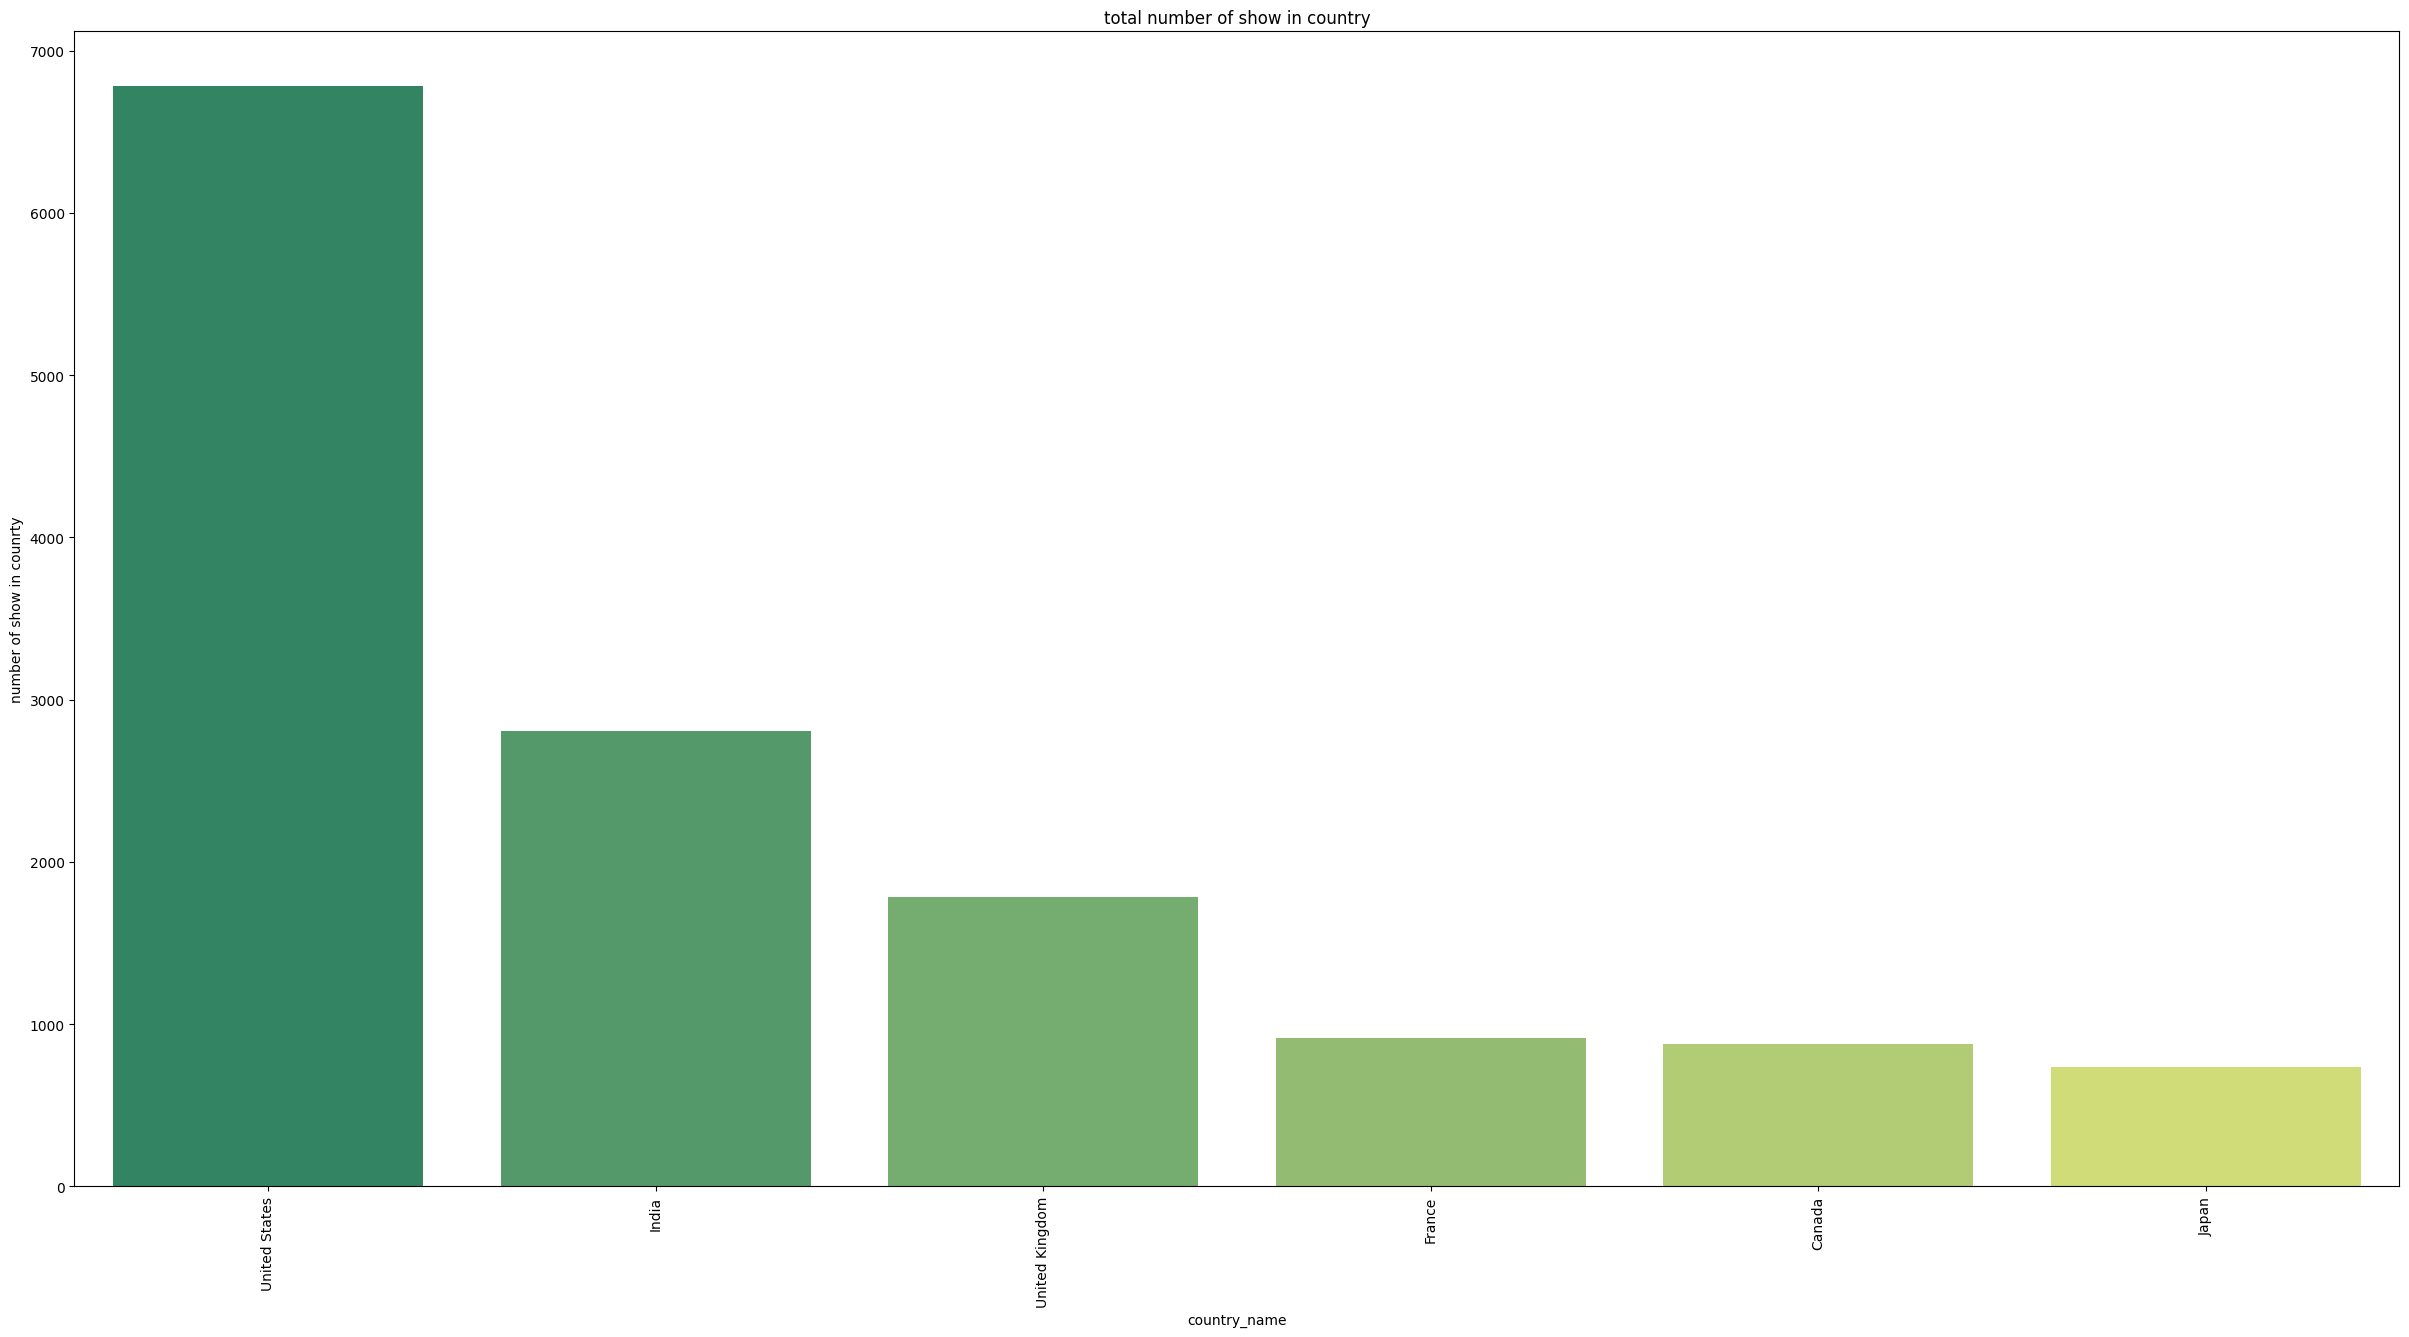

In [25]:
mp.figure(figsize=(30,15))
mp.xticks(rotation=90)
mp.xlabel('country_name')
mp.ylabel('number of show in counrty')
mp.title('total number of show in country')
sns.countplot(data=df_countries,x='new_country',palette='summer')


# Here we have make a chart to understand data more in clear way with the help of bar chart

1.  Now things are more clear we can clearly see that the country from which netflix make money is **United States**

2. Other country are also important like India,France but they share less than United States

1.   **Important** thing to note is that United States share more **than sum of other 3 country contribution**





/tmp/ipykernel_5639/2427019310.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='listed_in_new',data=data,palette="cool_r")


<Axes: title={'center': 'total number of listed show'}, xlabel='listed_name', ylabel='number of show'>

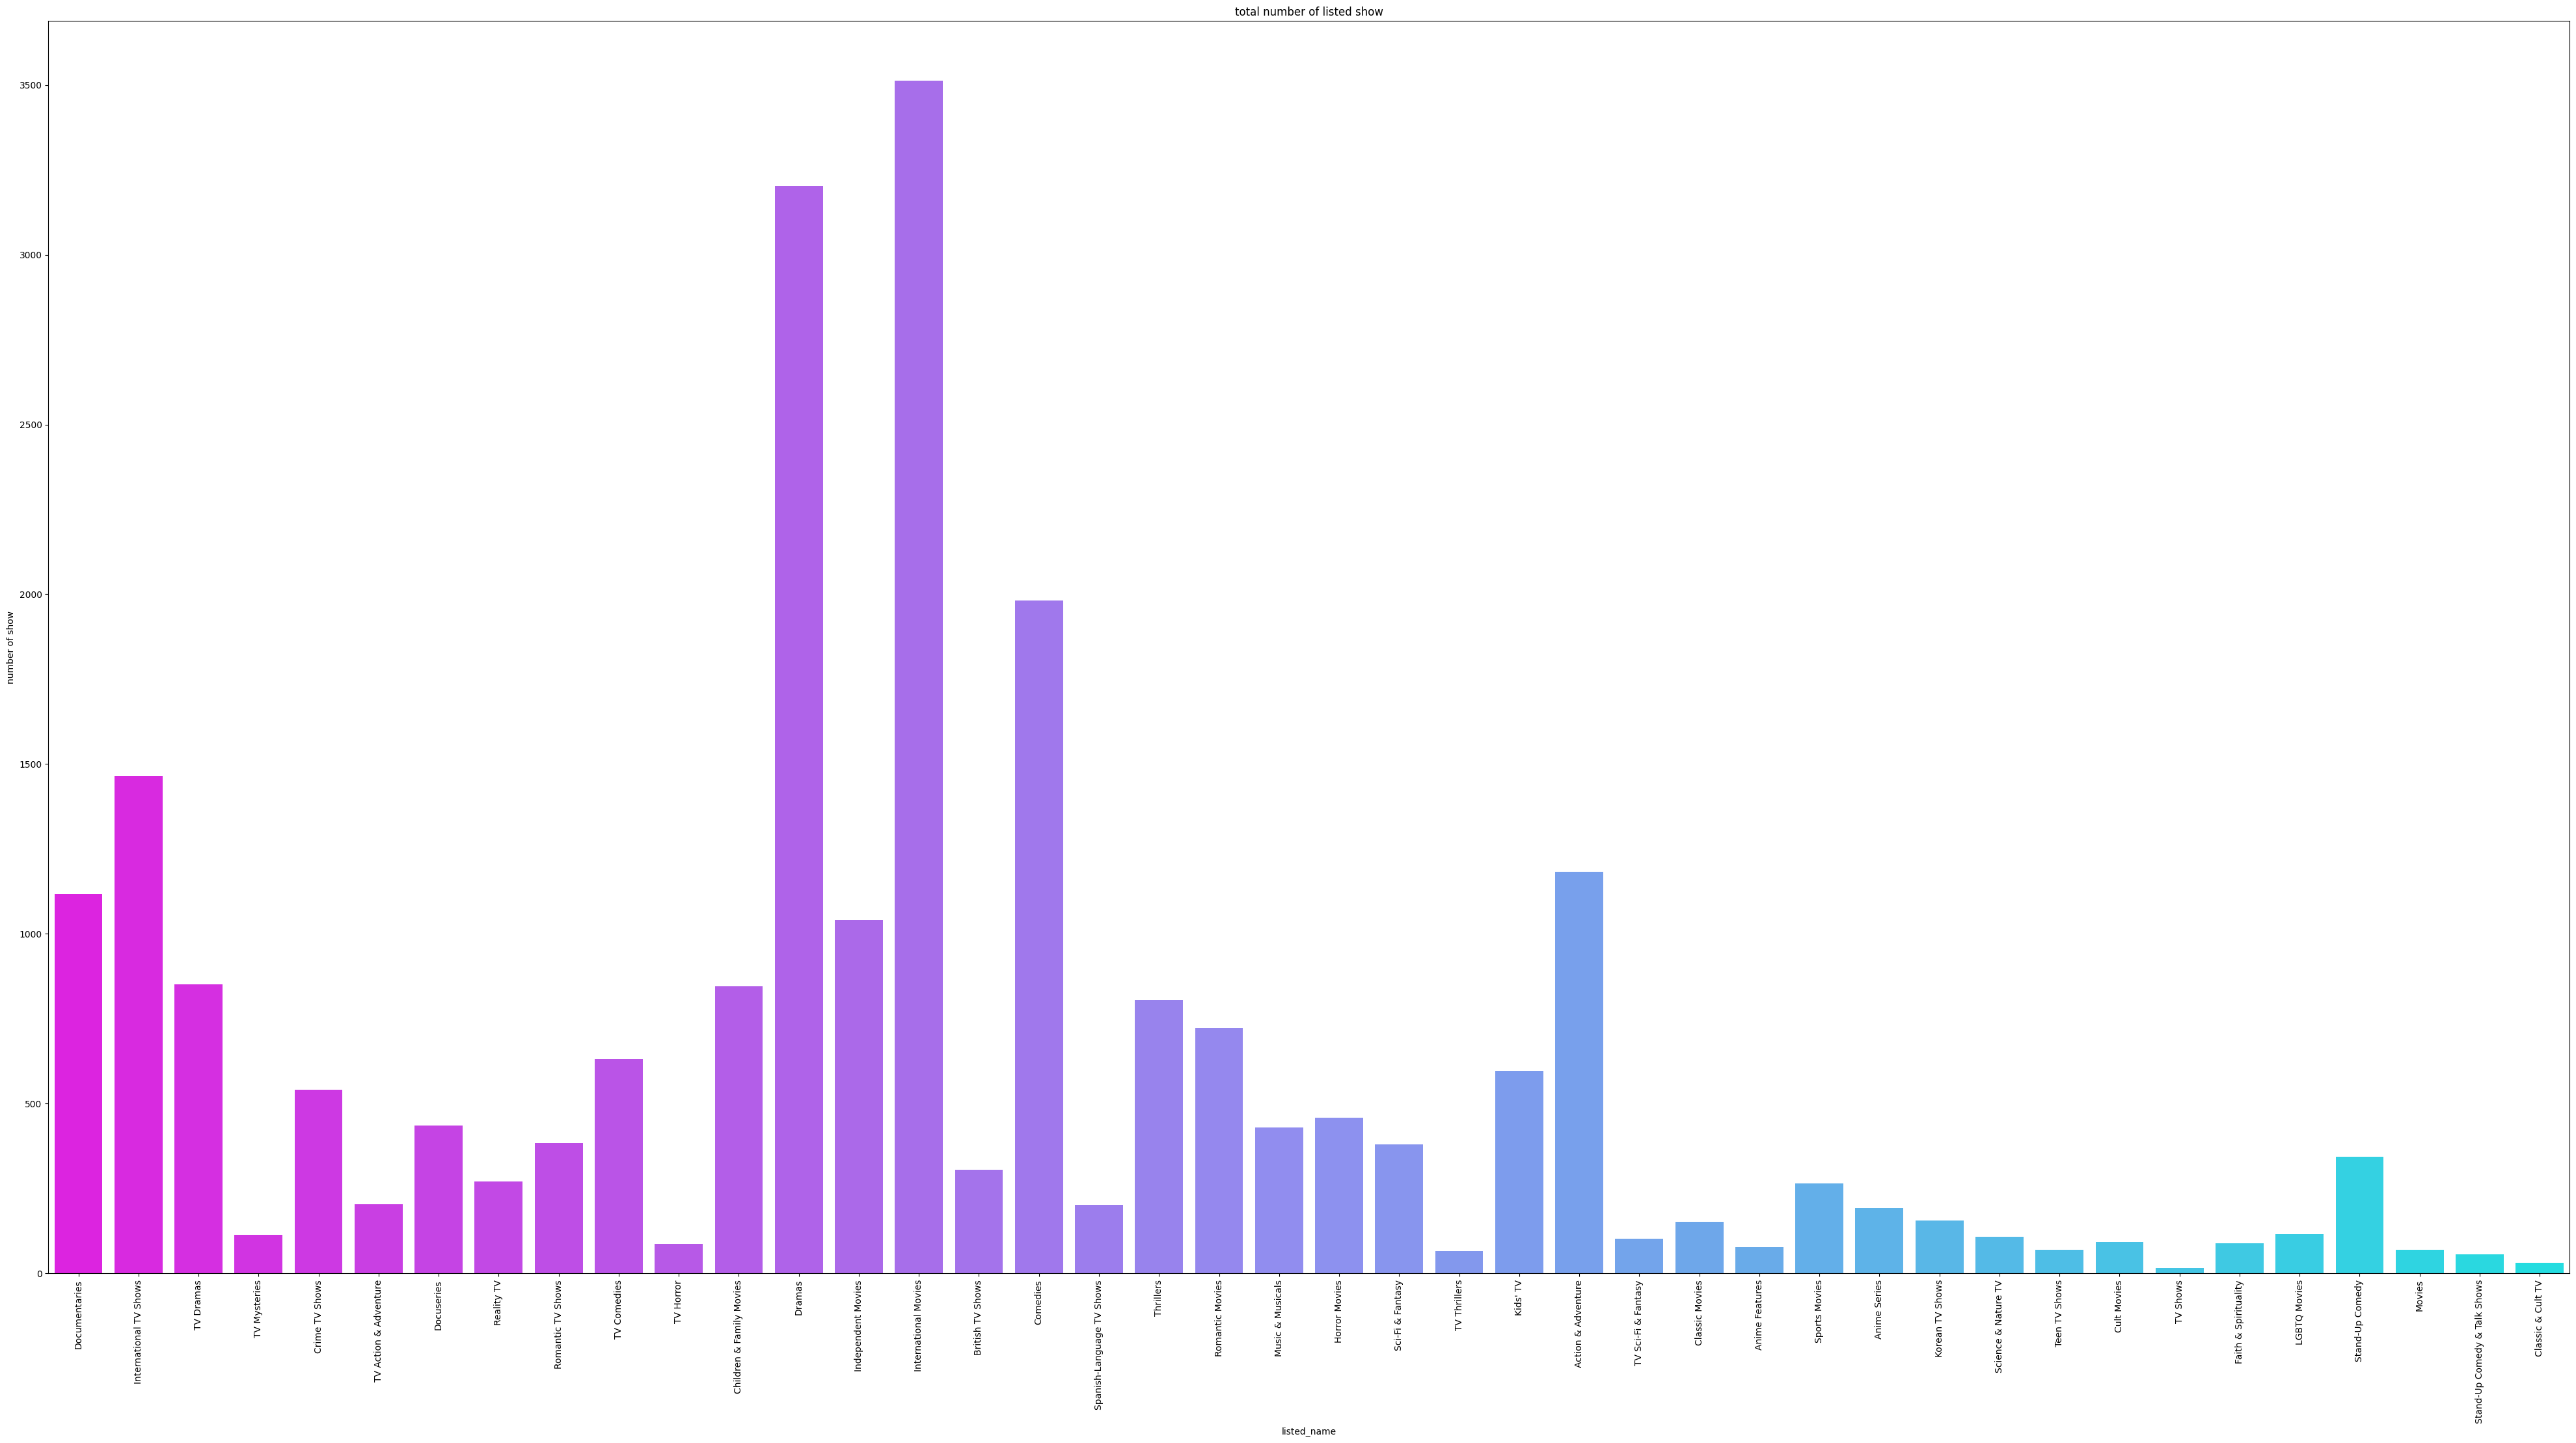

In [26]:
mp.figure(figsize=(50,25))
mp.xlabel('listed_name')
mp.ylabel("number of show")
mp.title("total number of listed show")
mp.xticks(rotation=90)
sns.countplot(x='listed_in_new',data=data,palette="cool_r")


# Here we have again same problem many thing but they dont play much ipm role so we will again remove some part

In [27]:

major_listed = [
    'Comedies', 'TV Comedies',
    'Dramas', 'TV Dramas',
    'International Movies', 'International TV Shows'
]
df = data[data['listed_in_new'].isin(major_listed)].copy()
print("Distribution of content types per genre label:")
print(df.groupby(['listed_in_new', 'type']).size())

Distribution of content types per genre label:
listed_in_new           type   
Comedies                Movie      1981
Dramas                  Movie      3202
International Movies    Movie      3513
International TV Shows  TV Show    1465
TV Comedies             TV Show     630
TV Dramas               TV Show     852
dtype: int64


# Now we have remove some data so we can easly analysis data properly and we have taken which play much important role

/tmp/ipykernel_5639/175064908.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='listed_in_new',data=df,palette="autumn_r")


<Axes: title={'center': 'total number of listed show'}, xlabel='listed_name', ylabel='number of show'>

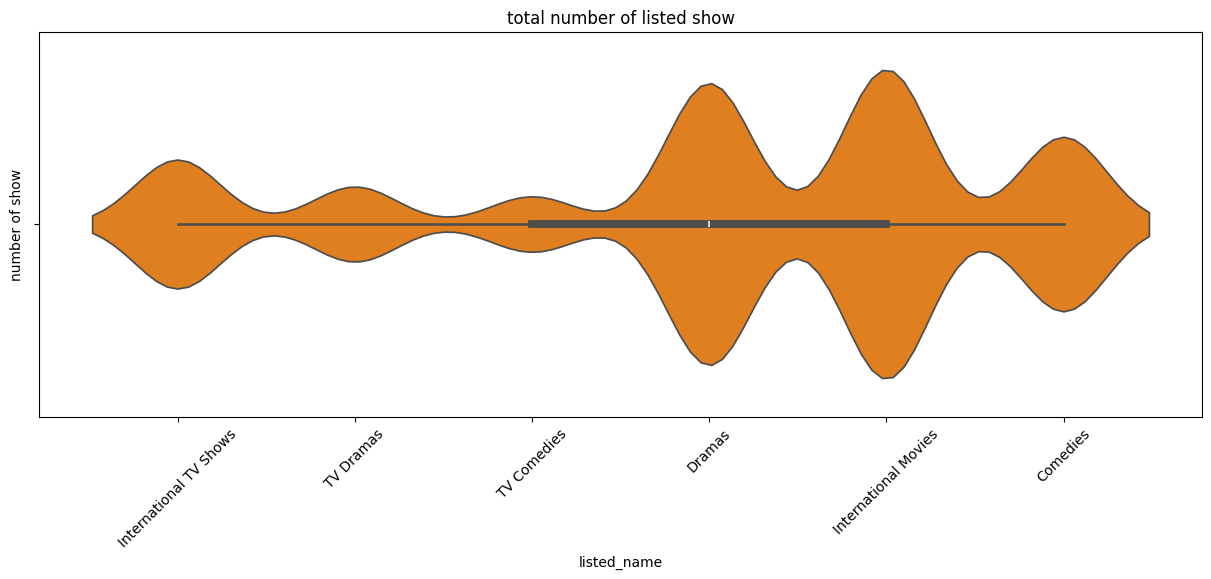

In [28]:
mp.figure(figsize=(15,5))
mp.xlabel('listed_name')
mp.ylabel("number of show")
mp.title("total number of listed show")
mp.xticks(rotation=45)
sns.violinplot(x='listed_in_new',data=df,palette="autumn_r")

# Here also we make chart so we can understand data more and to understant it become easy by help of this violin chart

1.   Now in it we can see that category like **Drama** and **comedies** play more imp role in data and other are not that high
2.   other catogery like **Documentaries** ,**Independent Movies**, **Action** are also important but not as high as **Drama**



In [29]:
data['type'].value_counts()

,count
type,
Movie,16883
TV Show,6881


# Here we have compare two category **Movies** and **TV_Show** so that we understand which category is use full and which category people love more

1.   From this we understand people love to watch movie more than TV_Show
2.   It may happen because of duration also mabe not



/tmp/ipykernel_5639/2826571209.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x="type", palette="winter")


([0, 1], [Text(0, 0, 'Movie'), Text(1, 0, 'TV Show')])

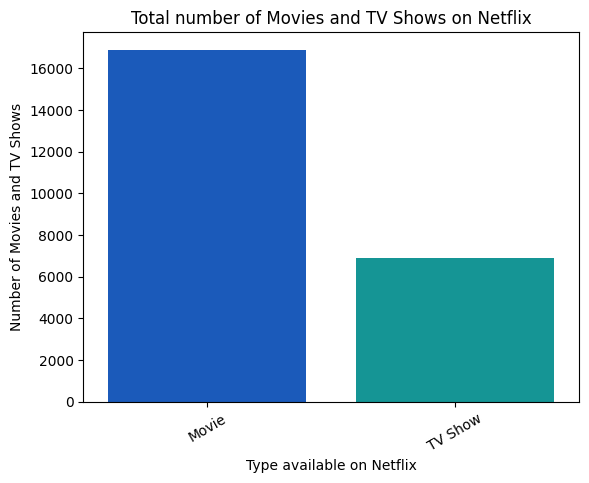

In [30]:
sns.countplot(data=data, x="type", palette="winter")
mp.xlabel("Type available on Netflix")
mp.ylabel("Number of Movies and TV Shows")
mp.title("Total number of Movies and TV Shows on Netflix")
mp.xticks(rotation=30)



# Now we have make graph also so that we can understand it more easly

*   It also show same thing that Movies are more loved in netflix more than TV_Show




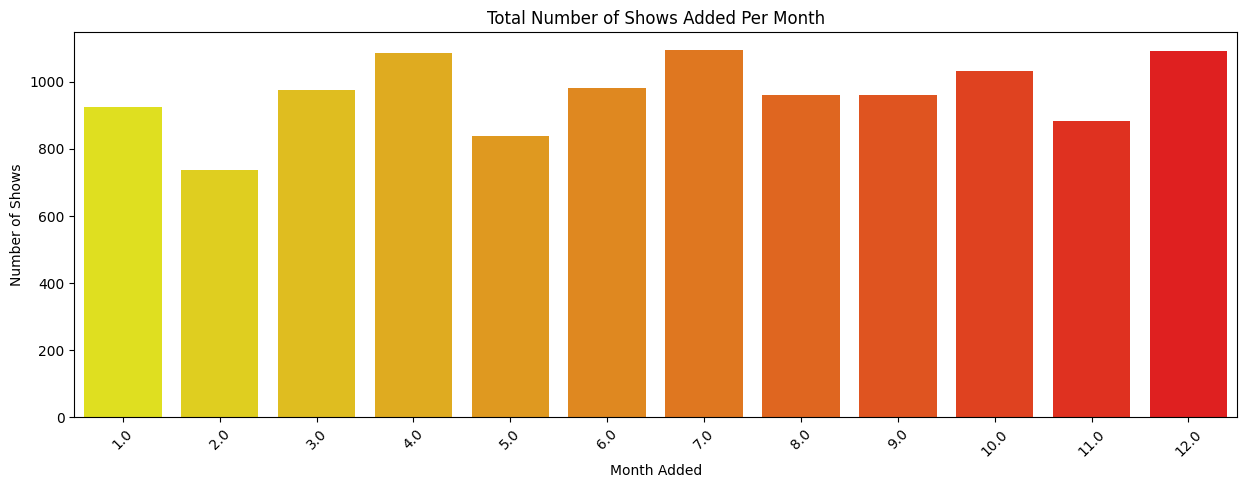

In [31]:
mp.figure(figsize=(15,5))
mp.xlabel('Month Added')
mp.ylabel("Number of Shows")
mp.title("Total Number of Shows Added Per Month")
mp.xticks(rotation=45)


sns.countplot(x='months_added', data=df.reset_index(drop=True), palette="autumn_r", hue='months_added', legend=False)
mp.show()

Here we make a chart to understand number of movies netflix released in each month

1.   Here we got that netflix released more movie on month no **4,7,12** because on that time many films are release and they released on netflix
2.   And less movie on **5** and **2** month this may happen people may watch less movies on that months



/tmp/ipykernel_5639/3439304570.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  sns.countplot(x='year_added', data=data.reset_index(drop=True), color="#1f77b4", hue='year_added', legend=False)


<Axes: title={'center': 'Total Number of Shows Added Per Year'}, xlabel='Year Added', ylabel='Number of Shows'>

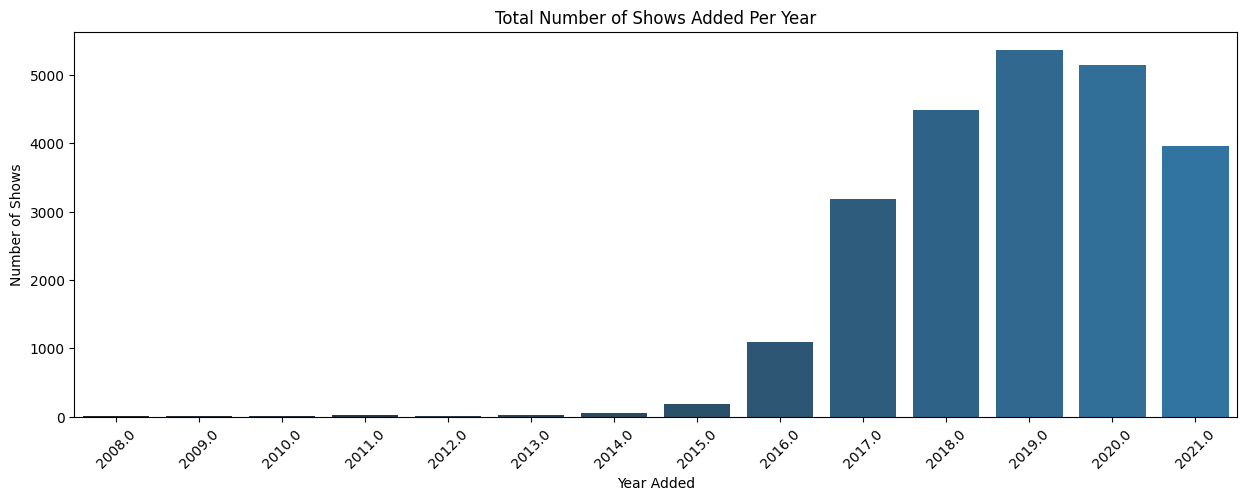

In [32]:
mp.figure(figsize=(15,5))
mp.xlabel("Year Added")
mp.ylabel("Number of Shows")
mp.title("Total Number of Shows Added Per Year")
mp.xticks(rotation=45)
# Resetting index to fix the duplicate label error
sns.countplot(x='year_added', data=data.reset_index(drop=True), color="#1f77b4", hue='year_added', legend=False)

# Now as for months we make for year also

1.  Now we can clearly see that on starting months netflix is relased less movie beacuse at that time may be it was not famous and people may not watch movie in platform
2.   But from the year after 2018 it has start and many moviea and show got famous during that time and netflix start uploding **Movies** ans **Shows**



<Axes: title={'center': 'Total Number of Shows Per Rating'}, xlabel='Rating', ylabel='Number of Shows'>

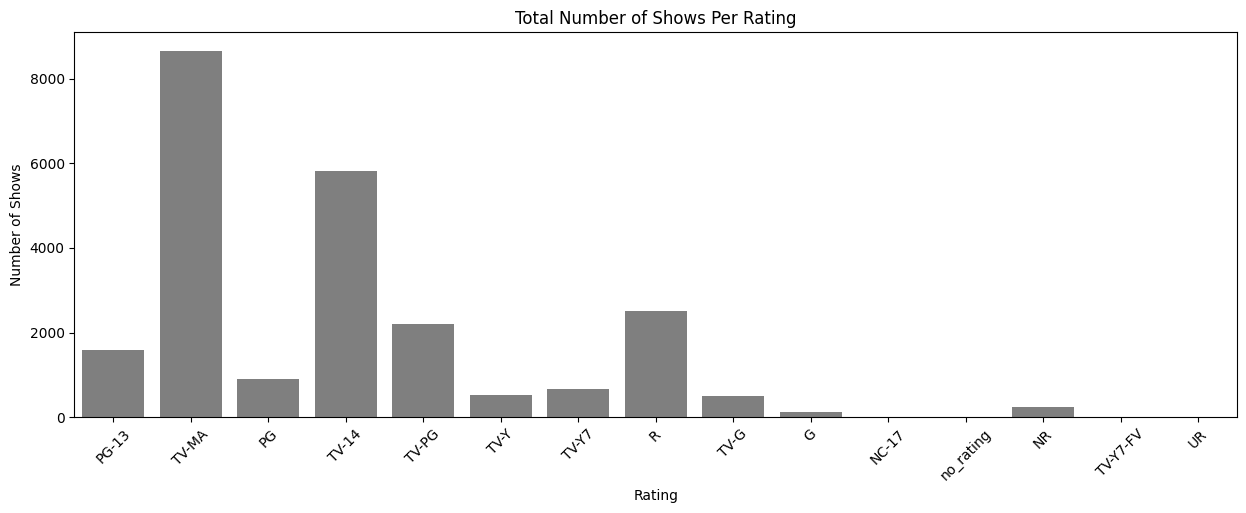

In [33]:
mp.figure(figsize=(15,5))
mp.xticks(rotation=45)
mp.xlabel("Rating")
mp.ylabel("Number of Shows")
mp.title("Total Number of Shows Per Rating")
sns.countplot(data=data,x="new_rating",color="#7f7f7f")


# Now we have make chart to analysis rating so we can see that which rating is or age group people are more there on netflix platform

1.   by this we can see that clearly people under 17 are more on netflix and less on above 18 means people love less bloody movie

1.   So they have to released more movie in this are group







## From here **BIVARIATE ANALYSIS** start

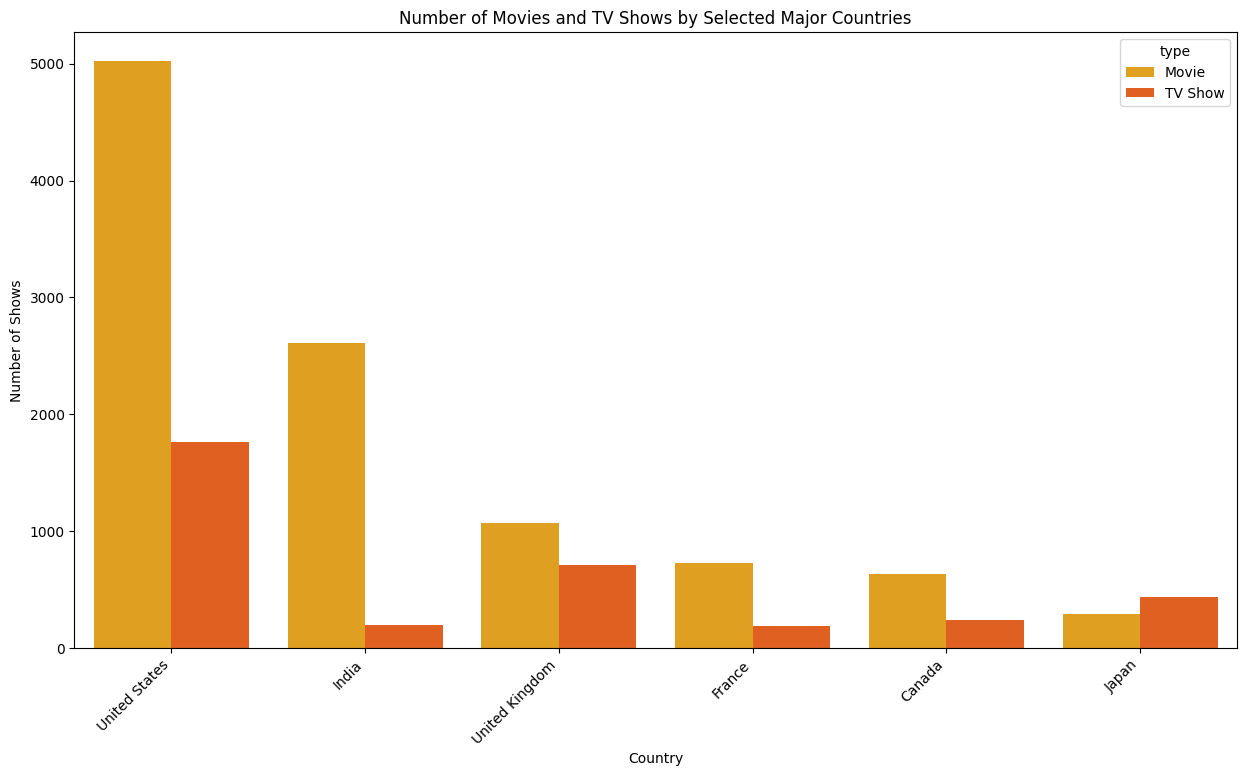

In [34]:
mp.figure(figsize=(15,8))
sns.countplot(data=df_countries, x='new_country', hue='type', palette='autumn_r')
mp.xlabel('Country')
mp.ylabel('Number of Shows')
mp.title('Number of Movies and TV Shows by Selected Major Countries')
mp.xticks(rotation=45, ha='right')
mp.show()

# Now we can see comparison between TV_Show and Movies from country

1. Here we can clearly see that in every country people normally love to watch movies



1.   Here something is different we can clearly see that people love to watch TV_Show in japan more than Movies










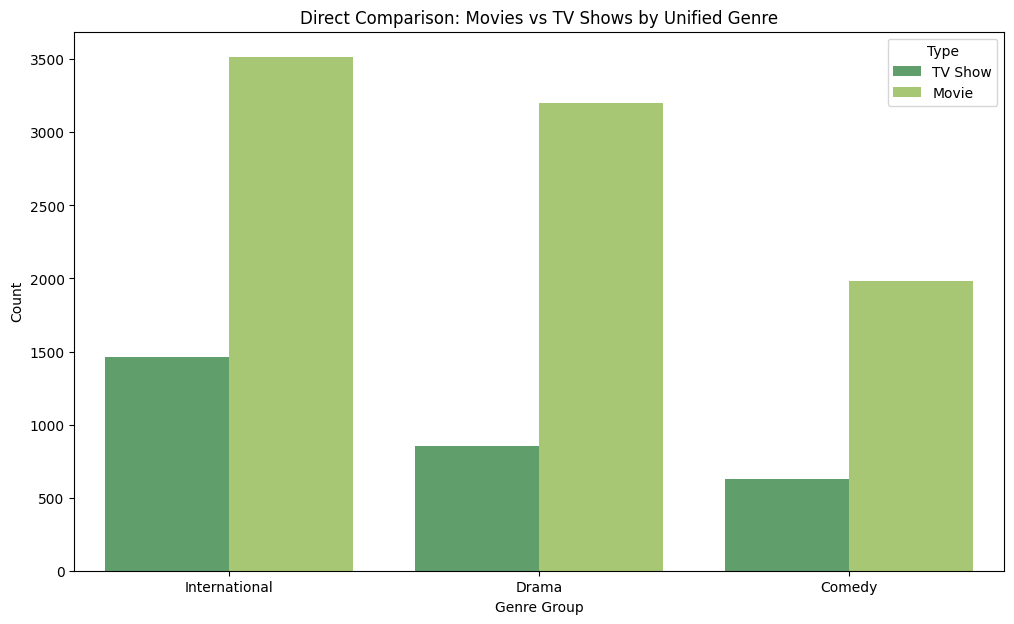

In [35]:

genre_map = {
    'Comedies': 'Comedy', 'TV Comedies': 'Comedy',
    'Dramas': 'Drama', 'TV Dramas': 'Drama',
    'International Movies': 'International', 'International TV Shows': 'International'
}


df_genres = data[data['listed_in_new'].isin(genre_map.keys())].copy()
df_genres['genre_group'] = df_genres['listed_in_new'].map(genre_map)
df_genres = df_genres.reset_index(drop=True)

mp.figure(figsize=(12,7))
sns.countplot(data=df_genres, x='genre_group', hue='type', palette='summer')
mp.xlabel('Genre Group')
mp.ylabel('Count')
mp.title('Direct Comparison: Movies vs TV Shows by Unified Genre')
mp.legend(title='Type')
mp.show()

# Here we make chart to understand each genre


1.   We can clearly see that in genre of movie drama and international movies are more popular than comadies
2.   Even in TV_Show also they ratio is same

*   So we can say that international and drama are best genre for any category for netflix  


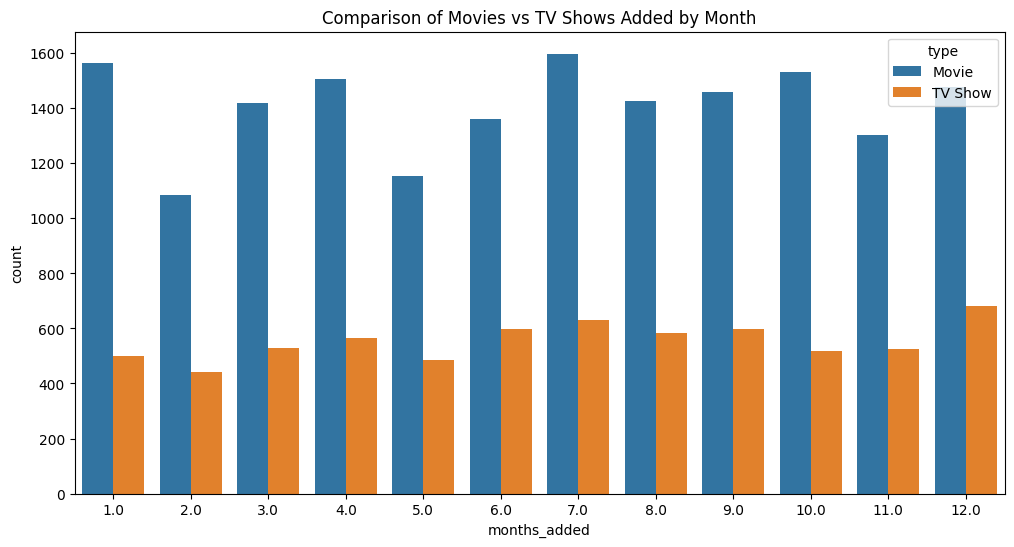

In [36]:

mp.figure(figsize=(12,6))
sns.countplot(x="months_added", data=data.reset_index(drop=True), palette="tab10", hue='type')
mp.title("Comparison of Movies vs TV Shows Added by Month")
mp.show()

# Now we have create chart for months wise data also to understand it more accurate

1.   Now as usual in it also movies got more priority than TV_Show and they are more released in every months also
2.   But we can see that there is no as such fluctuation in TV_Show data mean netflix released it properly  



<Axes: title={'center': 'Total Number of Shows Added Per Year'}, xlabel='Year Added', ylabel='Number of Shows'>

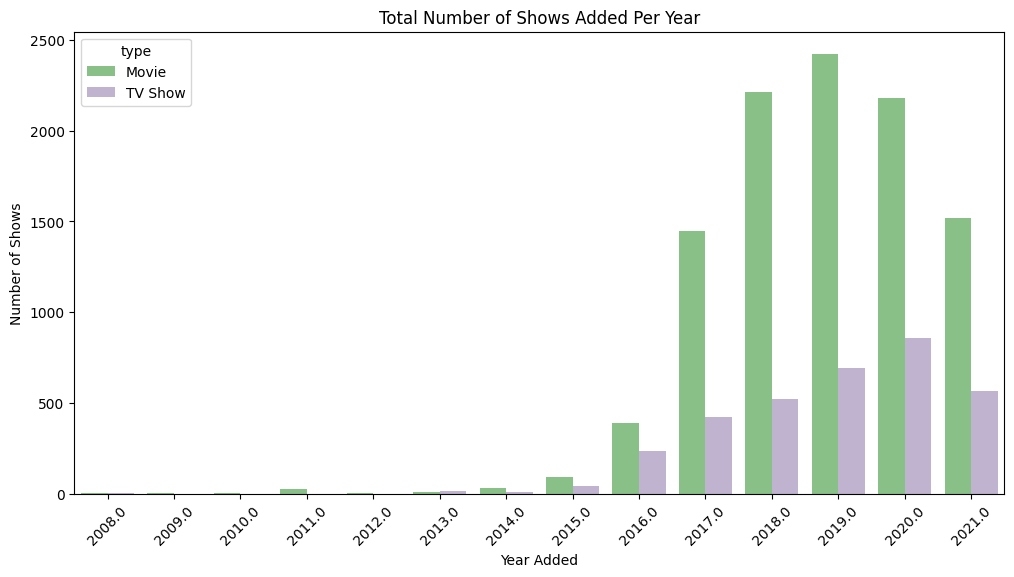

In [37]:
mp.figure(figsize=(12,6))
mp.xlabel("Year Added")
mp.ylabel("Number of Shows")
mp.title("Total Number of Shows Added Per Year")
mp.xticks(rotation=45)
sns.countplot(data=df_countries, x='year_added', hue='type', palette='Accent')

# Here we make chart for year wise data also  

1.   In it also we can see that Movies are more famous and relased than TV_Show
2.   So netflix also relased more Movies in every year



Text(0.5, 1.0, 'Total Number of Shows Per Rating in each category ')

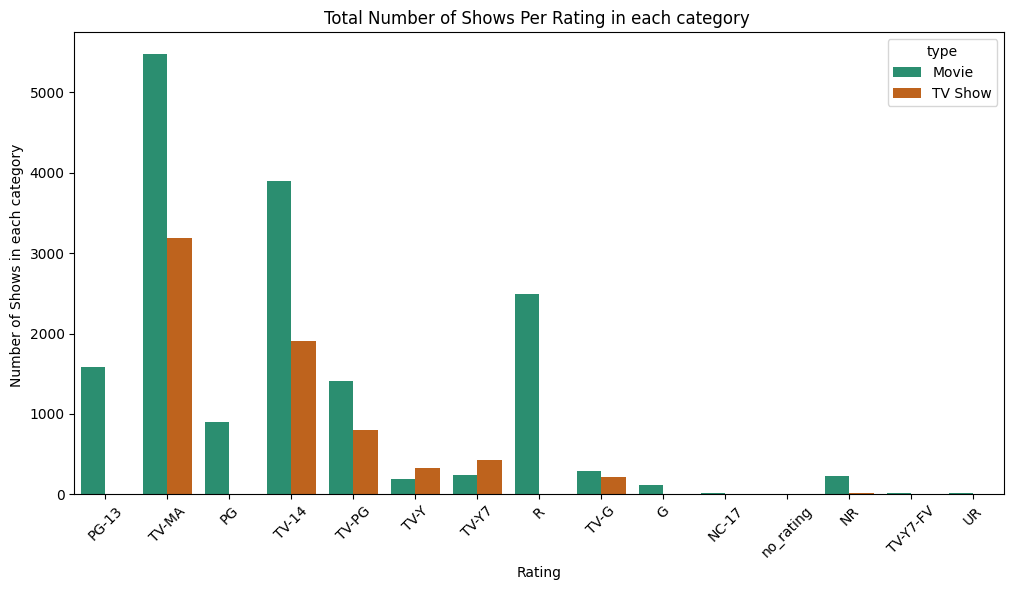

In [38]:
mp.figure(figsize=(12,6))
mp.xticks(rotation=45)
sns.countplot(data=data,x='new_rating',palette='Dark2',hue="type")
mp.xlabel("Rating")
mp.ylabel("Number of Shows in each category ")
mp.title("Total Number of Shows Per Rating in each category ")

# **CONCLUSION**

## This EDA of the Netflix Titles dataset highlights a catalogue that is movie-heavy, increasingly international, and oriented toward mature audiences. Content growth accelerated significantly between 2016 and 2019 before leveling off. These patterns offer a useful baseline for further analysis, such as genre-level trends within specific countries or predictive modelling of content popularity.